In [1]:
import pandas as pd
import numpy as np
from src.data_preprocessing import preprocess
from src.hourly_grouping import build_session_hours
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
df_raw = pd.read_csv("datasets/EVChargingStationUsage.csv")
df = preprocess(df_raw)
df.head(2)

[IDs -> strings]
[parse dates, drop invalid]
  dropped 249 rows with invalid or missing dates
[drop non-USD sessions and redundant columns]
  dropped 14 rows with currency MXN, EUR, CAD
  dropped columns: ['Country', 'Plug Type', 'Org Name', 'Currency', 'City', 'State/Province']
[clean station names]
[clean addresses]
[normalize MAC addresses]
[fill EVSE ID / Model Number from MAC]
  EVSE ID: filled 57,688 of 78,927 missing, 21,239 still missing
  Model Number: filled 57,688 of 78,927 missing, 21,239 still missing
[drop System S/N]
[fill missing categoricals with 'missing']
[add UTC columns]
[drop time zone mismatches]
  dropped 120 rows where start and end time zones are different
[validate durations and build duration columns]
  dropped 347 rows with missing or inconsistent duration (difference > 60 s)
[add time features]
[check Start <= End]
  OK: no rows with Start Date later than End Date
[remove outliers]
Sessions kept: 256,643 of 258,685 (failed plug-ins removed: 2,024, impossib

,Station Name,MAC Address,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),...,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day,year,month,day_of_week,site
0,HAMILTON 1,000D6F00015A9D76,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,6.249457,...,3.058889,1.900833,4169.0,1.158056,20,Evening,2011,7,4,HAMILTON
1,HAMILTON 1,000D6F00015A9D76,2011-07-30 00:00:00,PDT,2011-07-30 00:02:00,PDT,2011-07-30 00:02:00,0:02:06,0:01:54,0.106588,...,0.035000,0.031667,12.0,0.003333,0,Night,2011,7,5,HAMILTON


## Hourly intervals (from src/hourly_grouping)

In [3]:
hourly_events = build_session_hours(df)
hourly_events.head(10)

Hourly rows: 896,991 (on average 3.5 hours per session)


,session_id,User ID,Station Name,hour,occupied_h,charging_h,energy_kwh,idle_h
0,0,3284,HAMILTON 1,2011-07-29 20:00:00,0.716667,0.716667,2.356218,0.000000
1,0,3284,HAMILTON 1,2011-07-29 21:00:00,1.000000,1.000000,3.287746,0.000000
2,0,3284,HAMILTON 1,2011-07-29 22:00:00,1.000000,0.184167,0.605493,0.815833
3,0,3284,HAMILTON 1,2011-07-29 23:00:00,0.342222,0.000000,0.000000,0.342222
4,1,4169,HAMILTON 1,2011-07-30 00:00:00,0.035000,0.031667,0.106588,0.003333
5,2,4169,HAMILTON 1,2011-07-30 08:00:00,0.733333,0.733333,2.555198,0.000000
6,2,4169,HAMILTON 1,2011-07-30 09:00:00,1.000000,1.000000,3.484360,0.000000
7,2,4169,HAMILTON 1,2011-07-30 10:00:00,1.000000,1.000000,3.484360,0.000000
8,2,4169,HAMILTON 1,2011-07-30 11:00:00,1.000000,1.000000,3.484360,0.000000
9,2,4169,HAMILTON 1,2011-07-30 12:00:00,0.558889,0.557778,1.943499,0.001111


#### Quick analysus if the first sessions

First row from df - Hammilton 1, Start Date 2011-07-29 20:17, total duration sec 11012 (around 3h), charging duration 6843 (around 2h), energy 6.25. Then end of the charging would be 20:17 + 6843s = 22:11

20-21 (only 43 min = 0.71h) 

21- 22 (whole hour)

22-23 (only 11 min = 0.18h)

23-24 (only plugged in but not charging)

## User table - time preferences

In [4]:
def build_user_features(session_hours: pd.DataFrame, min_sessions: int = 10, verbose: bool = True) -> pd.DataFrame:
    blocks = ["night", "morning", "afternoon", "evening"]

    # 1. unknown users are not individual users
    unknown = session_hours["User ID"].isna() | session_hours["User ID"].isin(["missing", "0"])
    sh = session_hours.loc[~unknown].copy()

    # 2. keep users with enough sessions
    sessions_per_user = sh.groupby("User ID")["session_id"].nunique()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. timing: share of energy in each part of the day (hourly rows)
    sh["time_block"] = pd.cut(sh["hour"].dt.hour, [-1, 5, 11, 17, 23], labels=blocks)
    energy_total = sh.groupby("User ID")["energy_kwh"].sum()
    energy_by_block = (
        sh.groupby(["User ID", "time_block"], observed=False)["energy_kwh"].sum().unstack(fill_value=0)
    )
    shares = energy_by_block.div(energy_total, axis=0).add_prefix("share_energy_")
    # night is dropped: almost nobody charges at night (extremely skewed), and its share is
    # implied by the other three (night = 1 - morning - afternoon - evening)
    shares = shares.drop(columns="share_energy_night")

    # share of energy on Saturday and Sunday
    is_weekend = sh["hour"].dt.dayofweek >= 5
    energy_weekend = sh[is_weekend].groupby("User ID")["energy_kwh"].sum().reindex(energy_total.index, fill_value=0)
    shares["share_energy_weekend"] = energy_weekend / energy_total

    # 4. back to one row per session: typical charging and idle time, in minutes
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        occupied_h=("occupied_h", "sum"),
    )
    sess["charging_min"] = sess["charging_h"] * 60
    sess["idle_min"] = (sess["occupied_h"] - sess["charging_h"]) * 60
    by_user = sess.groupby("user")

    features = shares.join(pd.DataFrame({
        "median_charging_min": by_user["charging_min"].median(),
        "median_idle_min": by_user["idle_min"].median(),
    }))
    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,} "
              f"({len(keep) / len(sessions_per_user):.0%} of known users, "
              f"{sessions_per_user[keep].sum() / sessions_per_user.sum():.0%} of their sessions)")
        print(f"User features: {features.shape[0]:,} users x {features.shape[1]} features, "
              f"missing values: {int(features.isna().sum().sum())}")
    return features

In [5]:
user_features1 = build_user_features(hourly_events, min_sessions=10, verbose=True)
user_features1.head(3)

Users with at least 10 sessions: 3,579 (17% of known users, 84% of their sessions)
User features: 3,579 users x 6 features, missing values: 0


,share_energy_morning,share_energy_afternoon,share_energy_evening,share_energy_weekend,median_charging_min,median_idle_min
User ID,,,,,,
100243,0.079066,0.220512,0.607114,0.269483,143.666667,4.416667
100293,0.593211,0.038918,0.367870,0.613430,115.583333,33.233333
100523,0.124016,0.770184,0.105800,0.080989,94.441667,0.400000


## User table - intensity
(Experiments with different alternatives)

In [6]:
def build_user_features2(session_hours: pd.DataFrame,
                          min_sessions: int = 10,
                          verbose: bool = True) -> pd.DataFrame:

    # 1. Remove unknown users
    unknown = (
        session_hours["User ID"].isna() |
        session_hours["User ID"].isin(["missing", "0"])
    )
    sh = session_hours.loc[~unknown].copy()

    # 2. Keep users with enough sessions
    sessions_per_user = sh.groupby("session_id")["User ID"].first()
    sessions_per_user = sessions_per_user.value_counts()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. One row per session
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        energy_kwh=("energy_kwh", "sum")
    )

    # 4. Aggregate per user
    by_user = sess.groupby("user")

    features = pd.DataFrame({
        "n_sessions": by_user.size(),
        "total_energy_kwh": by_user["energy_kwh"].sum(),
        "median_energy_per_session": by_user["energy_kwh"].median(),
        "median_charging_min": by_user["charging_h"].median() * 60})

    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,}")
        print(f"User features A: {features.shape[0]:,} users x "
              f"{features.shape[1]} features, missing values: "
              f"{int(features.isna().sum().sum())}")

    return features

In [7]:
user_features2 = build_user_features2(hourly_events, min_sessions=10)
user_features2.head(3)

Users with at least 10 sessions: 3,579
User features A: 3,579 users x 4 features, missing values: 0


,n_sessions,total_energy_kwh,median_energy_per_session,median_charging_min
User ID,,,,
100243,649,5322.069112,7.407287,143.666667
100293,15,96.191890,6.336164,115.583333
100523,40,315.634840,7.343470,94.441667


<Axes: xlabel='total_energy_kwh', ylabel='Count'>

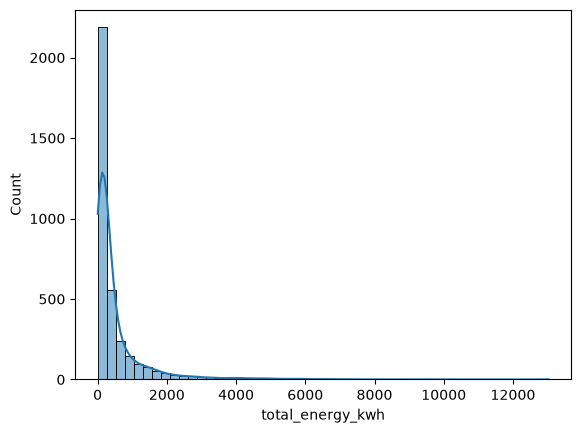

In [8]:
sns.histplot(
            user_features2["total_energy_kwh"],
            bins=50,
            kde=True,
        )

## User table 3 - effectiveness

In [9]:
def build_user_features3(session_hours: pd.DataFrame,
                          min_sessions: int = 10,
                          verbose: bool = True) -> pd.DataFrame:

    # 1. Remove unknown users
    unknown = (
        session_hours["User ID"].isna() |
        session_hours["User ID"].isin(["missing", "0"])
    )
    sh = session_hours.loc[~unknown].copy()

    # 2. Keep users with enough sessions
    sessions_per_user = sh.groupby("session_id")["User ID"].first()
    sessions_per_user = sessions_per_user.value_counts()
    keep = sessions_per_user[sessions_per_user >= min_sessions].index
    sh = sh[sh["User ID"].isin(keep)].copy()

    # 3. One row per session
    sess = sh.groupby("session_id").agg(
        user=("User ID", "first"),
        charging_h=("charging_h", "sum"),
        occupied_h=("occupied_h", "sum"),
        idle_h=("idle_h", "sum")
    )

    # Convert to minutes
    sess["charging_min"] = sess["charging_h"] * 60
    sess["occupied_min"] = sess["occupied_h"] * 60
    sess["idle_min"] = sess["idle_h"] * 60

    # Session-level ratios
    sess["charging_ratio"] = (
        sess["charging_h"] /
        sess["occupied_h"].replace(0, np.nan)
    )

    sess["idle_ratio"] = (
        sess["idle_h"] /
        sess["occupied_h"].replace(0, np.nan)
    )

    # 4. Aggregate per user
    by_user = sess.groupby("user")

    features = pd.DataFrame({
        "median_charging_min": by_user["charging_min"].median(),
        

        "median_occupied_min": by_user["occupied_min"].median(),
       

        "median_idle_min": by_user["idle_min"].median(),
        

        "median_charging_ratio": by_user["charging_ratio"].median(),
       
        "median_idle_ratio": by_user["idle_ratio"].median(),
        
    })

    features.index.name = "User ID"

    if verbose:
        print(f"Users with at least {min_sessions} sessions: {len(keep):,}")
        print(f"User features B: {features.shape[0]:,} users x "
              f"{features.shape[1]} features, missing values: "
              f"{int(features.isna().sum().sum())}")

    return features

In [10]:
user_features3 = build_user_features3(hourly_events, min_sessions=10)
user_features3.head(3)

Users with at least 10 sessions: 3,579
User features B: 3,579 users x 5 features, missing values: 0


,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio
User ID,,,,,
100243,143.666667,176.733333,4.416667,0.971761,0.028239
100293,115.583333,156.633333,33.233333,0.773678,0.226322
100523,94.441667,99.258333,0.400000,0.995909,0.004091


<Axes: xlabel='median_charging_min', ylabel='Count'>

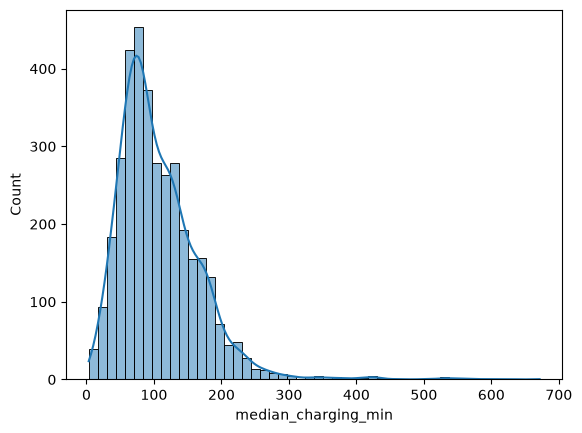

In [11]:
sns.histplot(
            user_features3["median_charging_min"],
            bins=50,
            kde=True,
        )

## K - Means 

Data preparation : log and Scaling

In [12]:
def K_means(dataset, LOG_FEATURES):
    X_raw = dataset.copy()
    print("Skośność przed:", X_raw.skew().round(2).to_dict())
    X_raw[LOG_FEATURES] = np.log1p(X_raw[LOG_FEATURES])
    print("Skośność po log1p:", X_raw[LOG_FEATURES].skew().round(2).to_dict())

    scaler = StandardScaler()
    X = pd.DataFrame(scaler.fit_transform(X_raw), index=X_raw.index, columns=X_raw.columns)
    assert not X.isna().any().any(), "są braki w cechach"
    print("Wejście do K-means:", X.shape)

    K_RANGE = range(2, 11)

    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        rows.append({
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "davies_bouldin": davies_bouldin_score(X, km.labels_),
        })

    k_scores = pd.DataFrame(rows).set_index("k")
    display(k_scores.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (col, title) in zip(axes, [
        ("inertia", "Inertia (szukaj łokcia)"),
        ("silhouette", "Silhouette (wyżej = lepiej)"),
        ("davies_bouldin", "Davies-Bouldin (niżej = lepiej)"),
    ]):
        ax.plot(k_scores.index, k_scores[col], marker="o")
        ax.set_title(title)
        ax.set_xlabel("K")
        ax.grid(True, alpha=0.3)
    sns.despine()
    plt.tight_layout()
    plt.show()

    return {
        "X_scaled": X,
        "X_transformed": X_raw,
        "scaler": scaler,
        "scores": k_scores
    }



In [13]:

def analyze_clusters(results, features_raw, K):
    
    # Scaled features from the previous function
    X_FINAL = results["X_scaled"]

    # Original features for cluster interpretation
    FEATURES = features_raw.loc[X_FINAL.index].copy()

    # Fit final K-means
    km_final = KMeans(
        n_clusters=K,
        n_init=50,
        random_state=42
    ).fit(X_FINAL)

    # Cluster labels
    labels = pd.Series(
        km_final.labels_,
        index=X_FINAL.index,
        name="Cluster"
    )

    # Centroids
    centroids = pd.DataFrame(
        km_final.cluster_centers_,
        columns=X_FINAL.columns
    ).rename_axis("klaster")

    # Metrics
    metrics = {
        "K": K,
        "silhouette": silhouette_score(X_FINAL, labels),
        "davies_bouldin": davies_bouldin_score(X_FINAL, labels),
        "inertia": km_final.inertia_
    }

    # Cluster profiles using original features
    prof = FEATURES.join(labels).groupby("Cluster").median()

    prof.insert(
        0,
        "users",
        labels.value_counts().sort_index()
    )

    prof.insert(
        1,
        "share_%",
        (100 * prof["users"] / prof["users"].sum()).round(1)
    )

    prof = prof.round(2)

    # Print metrics and profile
    print(f"--- K={K} ---")
    print(f"Silhouette: {metrics['silhouette']:.3f}")
    print(f"Davies-Bouldin: {metrics['davies_bouldin']:.3f}")
    print(f"Inertia: {metrics['inertia']:.2f}")

    display(prof)

    # Plot centroids
    fig, ax = plt.subplots(figsize=(10, 4))

    sns.heatmap(
        centroids,
        cmap="RdBu_r",
        center=0,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        ax=ax,
        cbar=False
    )

    ax.set_title(f"K={K} (z-score cech)")
    ax.set_ylabel("klaster")
    ax.tick_params(axis="x", rotation=35)

    plt.tight_layout()
    plt.show()

    return {
        "model": km_final,
        "labels": labels,
        "centroids": centroids,
        "profile": prof,
        "metrics": metrics
    }


Skośność przed: {'share_energy_morning': 1.09, 'share_energy_afternoon': 0.07, 'share_energy_evening': 0.8, 'share_energy_weekend': 0.81, 'median_charging_min': 2.14, 'median_idle_min': 9.25}
Skośność po log1p: {'median_idle_min': 1.73, 'median_charging_min': -0.52}
Wejście do K-means: (3579, 6)


,inertia,silhouette,davies_bouldin
k,,,
2,16387.046,0.241,1.655
3,13380.741,0.236,1.465
4,11393.557,0.235,1.397
5,10022.141,0.245,1.302
6,9209.241,0.227,1.321
7,8417.368,0.243,1.257
8,7736.376,0.253,1.217
9,7169.976,0.253,1.206
10,6655.034,0.241,1.205


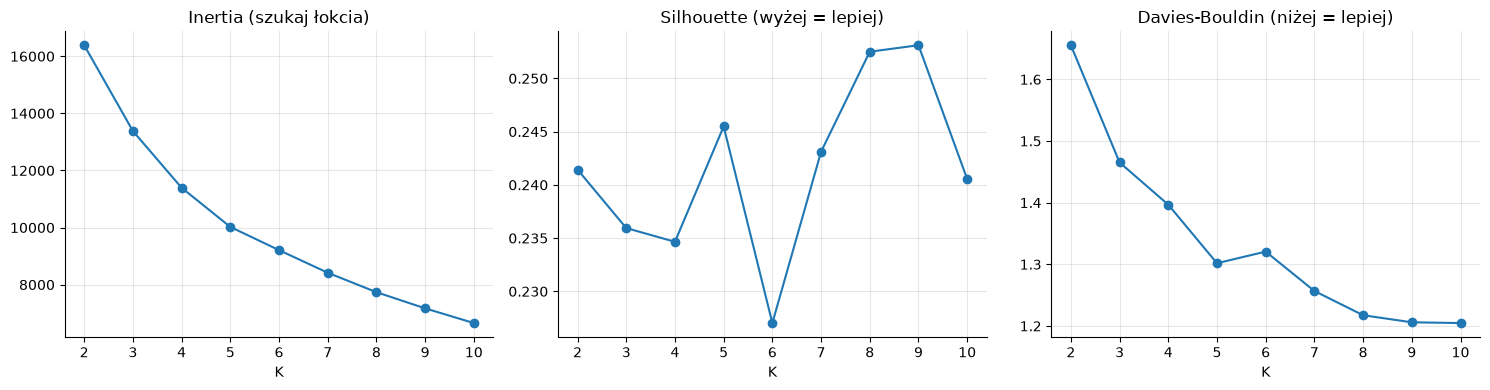

In [14]:
results1 = K_means(
    user_features1,
    LOG_FEATURES=["median_idle_min", "median_charging_min"]
)

--- K=5 ---
Silhouette: 0.246
Davies-Bouldin: 1.302
Inertia: 10022.11


,users,share_%,share_energy_morning,share_energy_afternoon,share_energy_evening,share_energy_weekend,median_charging_min,median_idle_min
Cluster,,,,,,,,
0,811,22.7,0.18,0.52,0.24,0.59,64.50,0.31
1,453,12.7,0.20,0.52,0.14,0.15,127.54,26.43
2,863,24.1,0.05,0.28,0.60,0.31,84.10,0.33
3,951,26.6,0.21,0.65,0.09,0.05,111.45,0.33
4,501,14.0,0.71,0.23,0.01,0.01,137.55,0.53


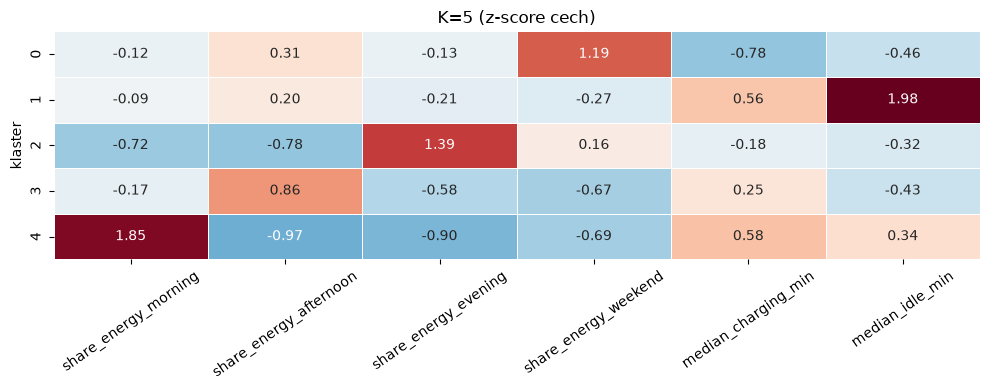

In [15]:
final1 = analyze_clusters(
    results=results1,
    features_raw=user_features1,
    K=5
)

Skośność przed: {'n_sessions': 4.73, 'total_energy_kwh': 5.02, 'median_energy_per_session': 2.64, 'median_charging_min': 2.14}
Skośność po log1p: {'total_energy_kwh': 0.54, 'median_energy_per_session': 0.07, 'median_charging_min': -0.52}
Wejście do K-means: (3579, 4)


,inertia,silhouette,davies_bouldin
k,,,
2,8413.277,0.398,0.997
3,6067.671,0.389,0.881
4,4606.642,0.338,0.921
5,3846.761,0.337,0.934
6,3295.451,0.298,0.971
7,2912.570,0.306,0.953
8,2623.772,0.288,0.963
9,2362.257,0.289,0.957
10,2200.348,0.290,0.948


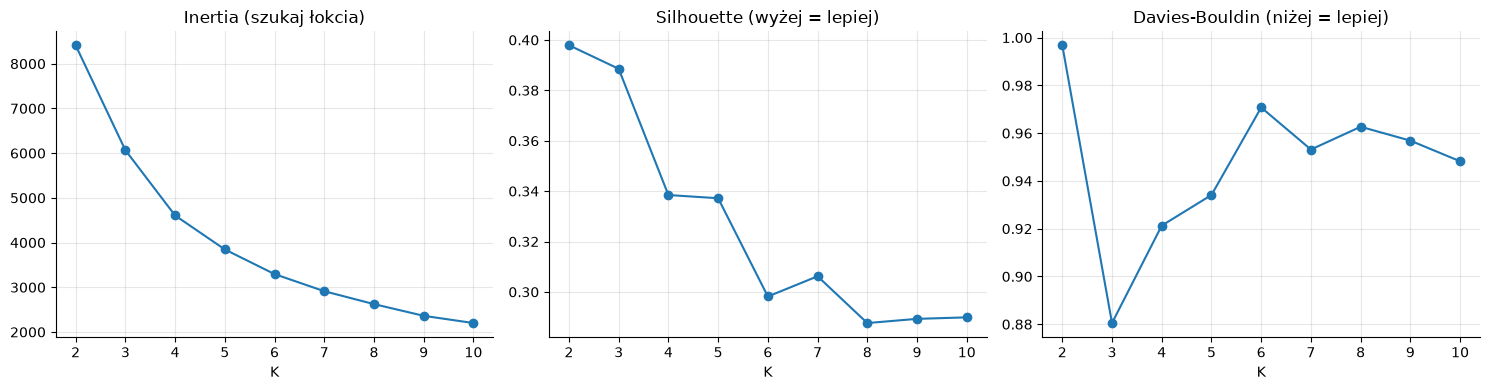

In [16]:
results2 =K_means(user_features2, LOG_FEATURES=[ "total_energy_kwh", "median_energy_per_session", "median_charging_min" ])

--- K=4 ---
Silhouette: 0.338
Davies-Bouldin: 0.921
Inertia: 4606.64


,users,share_%,n_sessions,total_energy_kwh,median_energy_per_session,median_charging_min
Cluster,,,,,,
0,1631,45.6,21.0,141.60,6.25,88.07
1,158,4.4,352.5,3201.19,8.58,131.58
2,772,21.6,18.0,59.82,2.84,47.28
3,1018,28.4,54.0,648.91,12.42,162.15


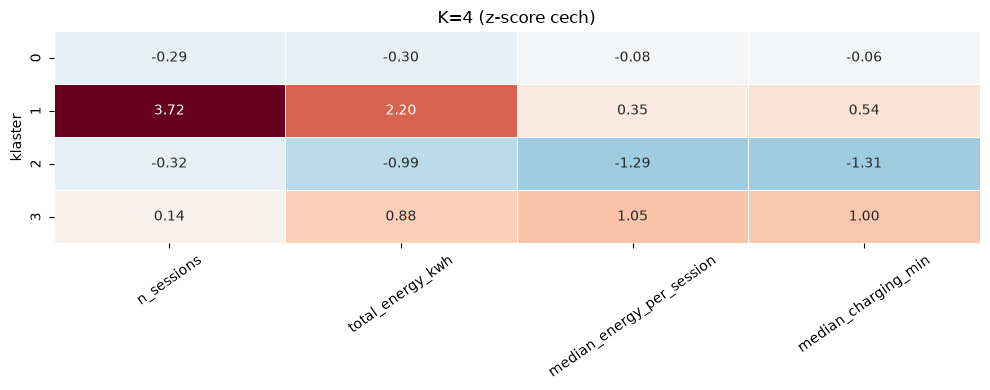

In [17]:
final2 = analyze_clusters(
    results=results2,
    features_raw=user_features2,
    K=4
)

Skośność przed: {'median_charging_min': 2.14, 'median_occupied_min': 2.9, 'median_idle_min': 9.25, 'median_charging_ratio': -3.39, 'median_idle_ratio': 3.39}
Skośność po log1p: {'median_charging_min': -0.52, 'median_occupied_min': -0.42, 'median_idle_min': 1.73, 'median_charging_ratio': -3.76, 'median_idle_ratio': 3.0}
Wejście do K-means: (3579, 5)


,inertia,silhouette,davies_bouldin
k,,,
2,9721.323,0.584,0.773
3,6178.489,0.446,0.750
4,4410.787,0.467,0.733
5,3324.234,0.463,0.709
6,2797.759,0.461,0.790
7,2380.375,0.426,0.780
8,2144.671,0.409,0.787
9,1928.937,0.410,0.802
10,1736.600,0.414,0.802


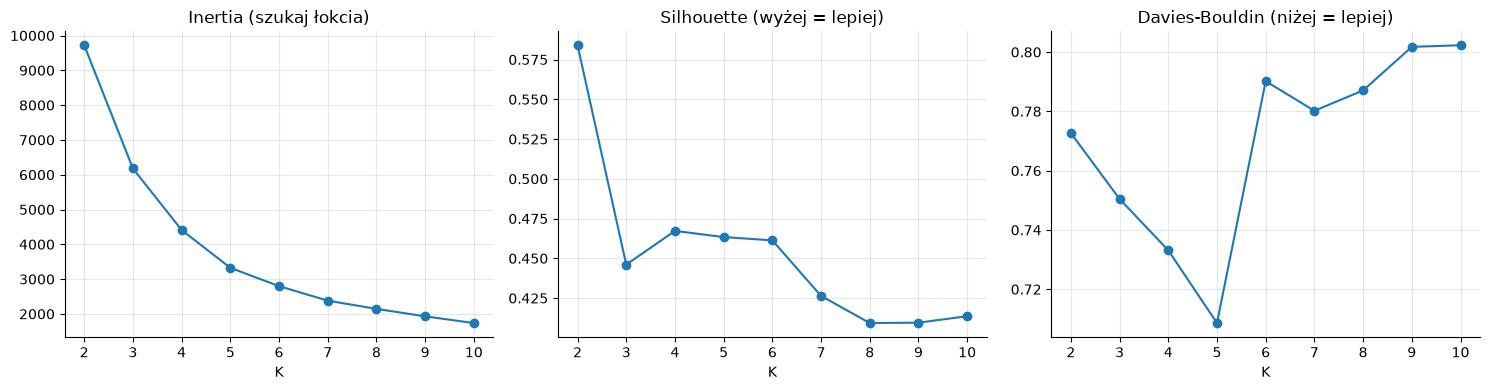

In [18]:
results3 = K_means(user_features3, LOG_FEATURES=[ "median_charging_min",  "median_occupied_min", "median_idle_min",  "median_charging_ratio",  "median_idle_ratio" ])

--- K=5 ---
Silhouette: 0.463
Davies-Bouldin: 0.709
Inertia: 3324.21


,users,share_%,median_charging_min,median_occupied_min,median_idle_min,median_charging_ratio,median_idle_ratio
Cluster,,,,,,,
0,1056,29.5,153.34,163.78,0.36,1.00,0.00
1,434,12.1,39.37,42.18,0.30,0.99,0.01
2,149,4.2,99.25,184.62,74.72,0.56,0.44
3,1436,40.1,76.69,82.82,0.32,0.99,0.01
4,504,14.1,127.33,160.10,20.93,0.86,0.14


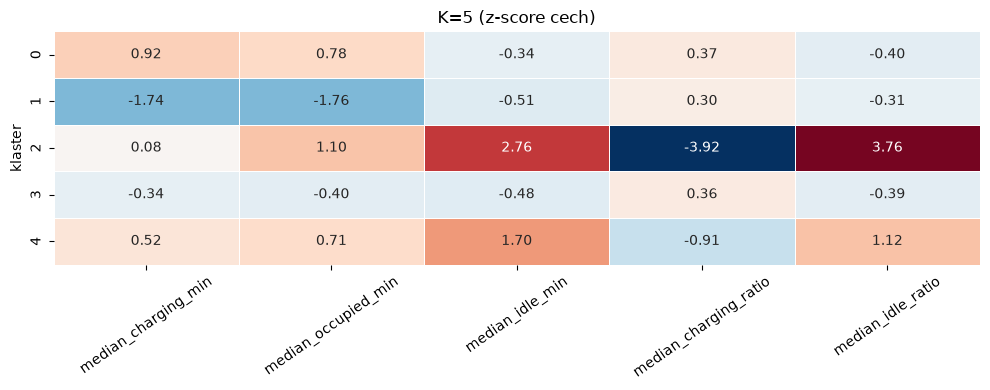

In [19]:
final3 = analyze_clusters(
    results=results3,
    features_raw=user_features3,
    K=5
) 
    

## Best one so far:

Silhouette is quite high 

Good cluster names (interpratation)

Cluster 0 : Long but efficient charging. These users charge for quite long, but charging time is mostly equal to total time 

Cluster 1: Short charging sessions with little idle time 

Cluster 2: Average charging time but a lot of idle minutes (idle dominated sessions)

Cluster 3: Regular,moderate users with regular charging time and not high idle minutes

Cluster 4: Long charging sessions with high idle. 

## Continue with cluster 3

## TO DO : Try other clustering algorithms 

In [76]:
labels = final3["labels"].copy()
labels.index = labels.index.astype(str)          

df_cl = df.copy()
df_cl["User ID"] = df_cl["User ID"].astype(str)
df_cl["Cluster"] = df_cl["User ID"].map(labels)  # NaN = user with no cluster



In [78]:
# ---------- shared style for all cluster charts ----------
CLUSTER_NAMES = {
    0: "Long, effective",
    1: "Short sessions",
    2: "Long idle",
    3: "Regular",
    4: "Long charging, long idle",
}
CLUSTER_ORDER = sorted(CLUSTER_NAMES)
CLUSTER_LABELS = {c: f"{c} · {n}" for c, n in CLUSTER_NAMES.items()}
CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, sns.color_palette("Set2", len(CLUSTER_ORDER))))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

# clustered sessions only, cluster as int (used by every analysis below)
dc = df_cl[df_cl["Cluster"].notna()].copy()
dc["Cluster"] = dc["Cluster"].astype(int)
dc["Start Date"] = pd.to_datetime(dc["Start Date"])
dc["End Date"] = pd.to_datetime(dc["End Date"])


def cluster_heatmap(table, title, xlabel="", cbar_label="% of cluster sessions", fmt=".0f",
                    cmap="Blues", figsize=None, center=None):
    # Heatmap with clusters as rows: readable names, annotated cells, labelled colour bar.
    figsize = figsize or (min(16, 1.2 * table.shape[1] + 5.5), 0.6 * table.shape[0] + 2)
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(table, annot=True, fmt=fmt, cmap=cmap, center=center, linewidths=1, linecolor="white",
                cbar_kws={"label": cbar_label, "shrink": 0.8}, ax=ax,
                yticklabels=[CLUSTER_LABELS[c] for c in table.index])
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

## 1. Preffered sites by cluster

Skipped small sites: ['SHERMAN']


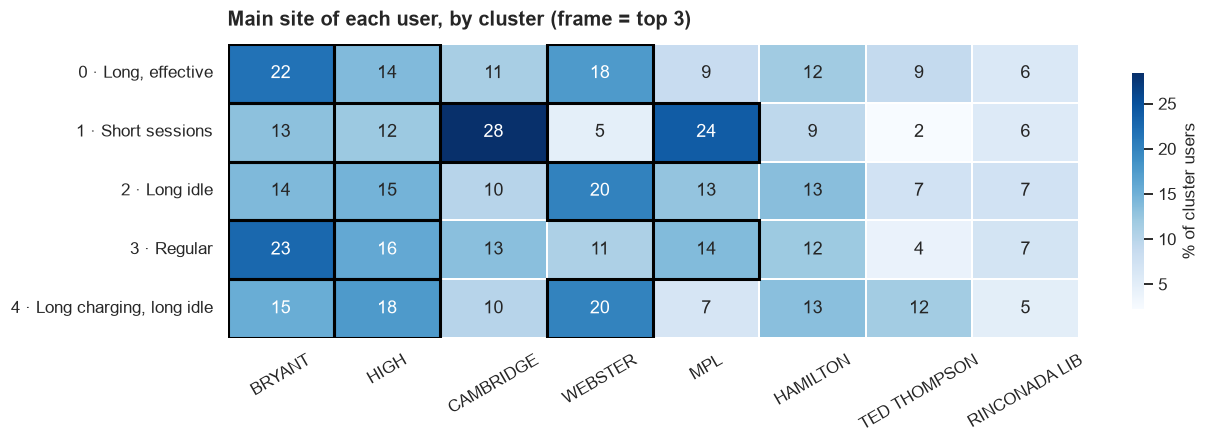

site  % users  % sessions  lift
cluster                      rank                                      
0 · Long, effective          1        BRYANT    21.69       19.82  1.09
                             2       WEBSTER    17.61       16.37  1.27
                             3          HIGH    13.92       16.62  0.92
1 · Short sessions           1     CAMBRIDGE    28.34       25.78  2.03
                             2           MPL    23.96       19.12  1.92
                             3        BRYANT    13.13       11.49  0.66
2 · Long idle                1       WEBSTER    20.13       21.12  1.46
                             2          HIGH    14.77       10.92  0.98
                             3        BRYANT    14.09       17.72  0.71
3 · Regular                  1        BRYANT    22.70       17.61  1.14
                             2          HIGH    16.02       14.88  1.06
                             3           MPL    13.86       15.30  1.11
4 · Long charging, long idle 1       WEBSTER    20.04       18.70  1.45
                             2          HIGH    17.66       14.01  1.17
                             3        BRYANT    15.48       14.54  0.78

In [79]:
TOP_N = 3                # how many sites to show per cluster
MIN_SITE_SHARE = 0.01    # skip sites with < 1% of sessions (e.g. SHERMAN)


def preferred_sites(dc, top_n=TOP_N, min_site_share=MIN_SITE_SHARE, plot=True):
    # 1. drop very small sites
    site_share = dc["site"].value_counts(normalize=True)
    small = site_share[site_share < min_site_share].index.tolist()
    if small:
        print("Skipped small sites:", small)
    d = dc[~dc["site"].isin(small)]

    # 2. each user's main site (the one with most of their sessions)
    per_user_site = d.groupby(["User ID", "site"]).size()
    users = pd.DataFrame({
        "Cluster": d.groupby("User ID")["Cluster"].first(),
        "main_site": per_user_site.groupby(level=0).idxmax().str[1],
        "main_site_share": per_user_site.groupby(level=0).max() / d.groupby("User ID").size(),
    })

    # 3. % of cluster users with a given main site, lift, % of cluster sessions
    site_order = users["main_site"].value_counts().index
    pct_users = pd.crosstab(users["Cluster"], users["main_site"], normalize="index")[site_order] * 100
    lift = pct_users / (users["main_site"].value_counts(normalize=True)[site_order] * 100)
    pct_sessions = pd.crosstab(d["Cluster"], d["site"], normalize="index")[site_order] * 100

    # 4. top-N table
    rows = []
    for c in pct_users.index:
        for rank, site in enumerate(pct_users.loc[c].nlargest(top_n).index, start=1):
            rows.append({"cluster": CLUSTER_LABELS[c], "rank": rank, "site": site,
                         "% users": pct_users.loc[c, site], "% sessions": pct_sessions.loc[c, site],
                         "lift": lift.loc[c, site]})
    top = pd.DataFrame(rows).set_index(["cluster", "rank"]).round(2)

    # 5. heatmap with top-N framed
    if plot:
        fig, ax = plt.subplots(figsize=(12, 4.2))
        sns.heatmap(pct_users, annot=True, fmt=".0f", cmap="Blues", ax=ax, linewidths=1, linecolor="white",
                    cbar_kws={"label": "% of cluster users", "shrink": 0.8},
                    yticklabels=[CLUSTER_LABELS[c] for c in pct_users.index])
        for i, c in enumerate(pct_users.index):
            for site in pct_users.loc[c].nlargest(top_n).index:
                j = pct_users.columns.get_loc(site)
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", lw=2))
        ax.set_title(f"Main site of each user, by cluster (frame = top {top_n})", loc="left")
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", rotation=30)
        plt.tight_layout()
        plt.show()

    return {"top": top, "pct_users": pct_users.round(1), "lift": lift.round(2),
            "pct_sessions": pct_sessions.round(1), "users": users}


site_pref = preferred_sites(dc)
display(site_pref["top"])

#### Conclusions 
 
 * not a very useful distinction. Webster, High and Bryant seem to be the most preffered across all clusters.

 * Cluster 1 (short sessions) is the only one with a clear preference towards Cambridge and MPL

 * Location is a weak descriptor of the clusters; behavior is a trait of a user, not a station


## 2. Idle time by station and who causes it

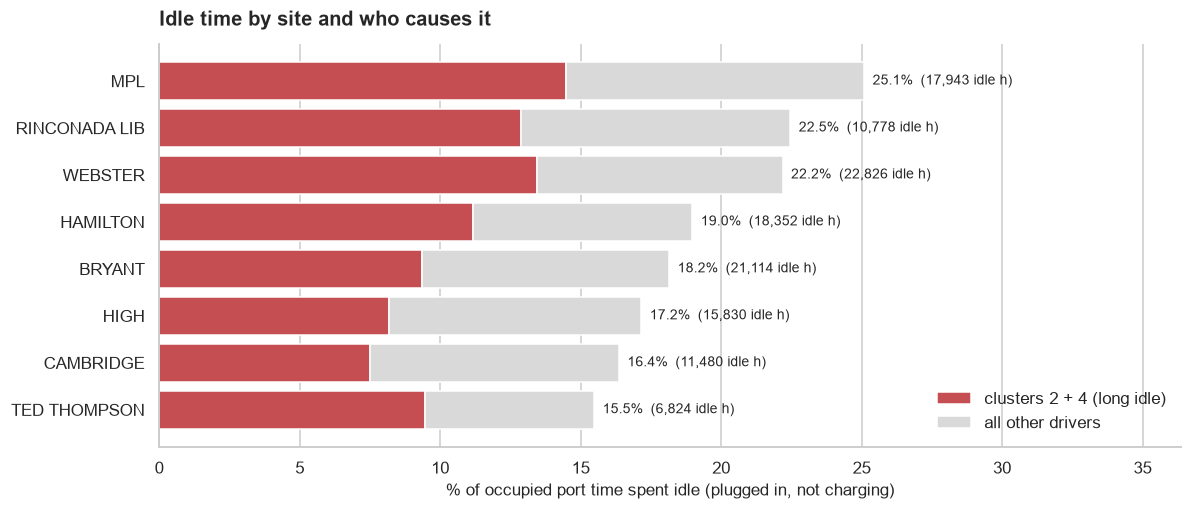

,sessions,occupied_h,idle_h,idle_h_clusters_2_4,% idle of occupied time,% of idle from clusters 2+4
site,,,,,,
MPL,28021,71512.7,17942.8,10361.2,25.1,57.7
RINCONADA LIB,18125,47985.9,10778.4,6184.3,22.5,57.4
WEBSTER,37286,102873.9,22825.7,13823.2,22.2,60.6
HAMILTON,38141,96712.6,18352.2,10816.6,19.0,58.9
BRYANT,46386,116315.1,21113.9,10873.0,18.2,51.5
HIGH,39470,92242.2,15829.6,7538.5,17.2,47.6
CAMBRIDGE,32580,70157.3,11479.8,5259.3,16.4,45.8
TED THOMPSON,16591,44077.7,6824.4,4175.8,15.5,61.2


In [80]:
big_sites = dc["site"].value_counts(normalize=True)
big_sites = big_sites[big_sites >= MIN_SITE_SHARE].index
d_all = df_cl[df_cl["site"].isin(big_sites)]          # all sessions (also users without cluster)
idle_clusters = d_all["Cluster"].isin([2, 4])

site_idle = pd.DataFrame({
    "sessions": d_all.groupby("site").size(),
    "occupied_h": d_all.groupby("site")["total_duration_hours"].sum(),
    "idle_h": d_all.groupby("site")["idle_hours"].sum(),
    "idle_h_clusters_2_4": d_all[idle_clusters].groupby("site")["idle_hours"].sum(),
})
site_idle["% idle of occupied time"] = 100 * site_idle["idle_h"] / site_idle["occupied_h"]
site_idle["% of idle from clusters 2+4"] = 100 * site_idle["idle_h_clusters_2_4"] / site_idle["idle_h"]
site_idle = site_idle.sort_values("% idle of occupied time")

# chart: idle share of occupied time, split into clusters 2+4 vs everyone else
part_24 = site_idle["% idle of occupied time"] * site_idle["% of idle from clusters 2+4"] / 100
part_rest = site_idle["% idle of occupied time"] - part_24

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(site_idle.index, part_24, color="#c44e52", label="clusters 2 + 4 (long idle)")
ax.barh(site_idle.index, part_rest, left=part_24, color="#d9d9d9", label="all other drivers")
for i, site in enumerate(site_idle.index):
    ax.text(site_idle.loc[site, "% idle of occupied time"] + 0.3, i,
            f"{site_idle.loc[site, '% idle of occupied time']:.1f}%  ({site_idle.loc[site, 'idle_h']:,.0f} idle h)",
            va="center", fontsize=9)
ax.set_xlim(0, site_idle["% idle of occupied time"].max() * 1.45)
ax.set_xlabel("% of occupied port time spent idle (plugged in, not charging)")
ax.set_title("Idle time by site and who causes it", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(site_idle.sort_values("% idle of occupied time", ascending=False).round(1))

### Cocnlusions 

* This plot shows that MLP and Riconda sites have the higest % of idle time. These sites are next to libraries so probably people leave their cars there. 

* Cluster interpratation : We can see that users from clusters 2 and 4 cause the majority of idle time on ALL stations. 

* This illustrates that the problem is present network-wise (and not only on some sites). Therefore local solutions wont be enough

## 3. When do clusters charge?

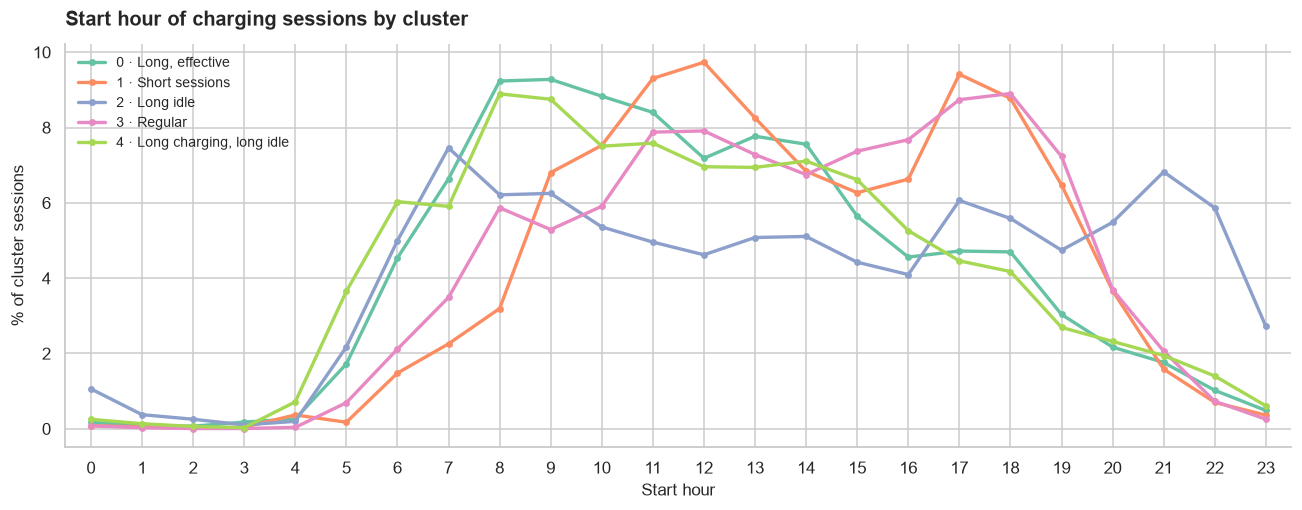

In [81]:
# 3a. start hour: line per cluster (each line sums to 100%)
dc["start_hour"] = dc["Start Date"].dt.hour
hourly_cluster = pd.crosstab(dc["start_hour"], dc["Cluster"], normalize="columns").reindex(range(24), fill_value=0) * 100

fig, ax = plt.subplots(figsize=(12, 4.8))
for c in CLUSTER_ORDER:
    ax.plot(hourly_cluster.index, hourly_cluster[c], marker="o", ms=3.5, lw=2.2,
            color=CLUSTER_COLORS[c], label=CLUSTER_LABELS[c])
ax.set_xticks(range(24))
ax.set_xlim(-0.5, 23.5)
ax.set_xlabel("Start hour")
ax.set_ylabel("% of cluster sessions")
ax.set_title("Start hour of charging sessions by cluster", loc="left")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

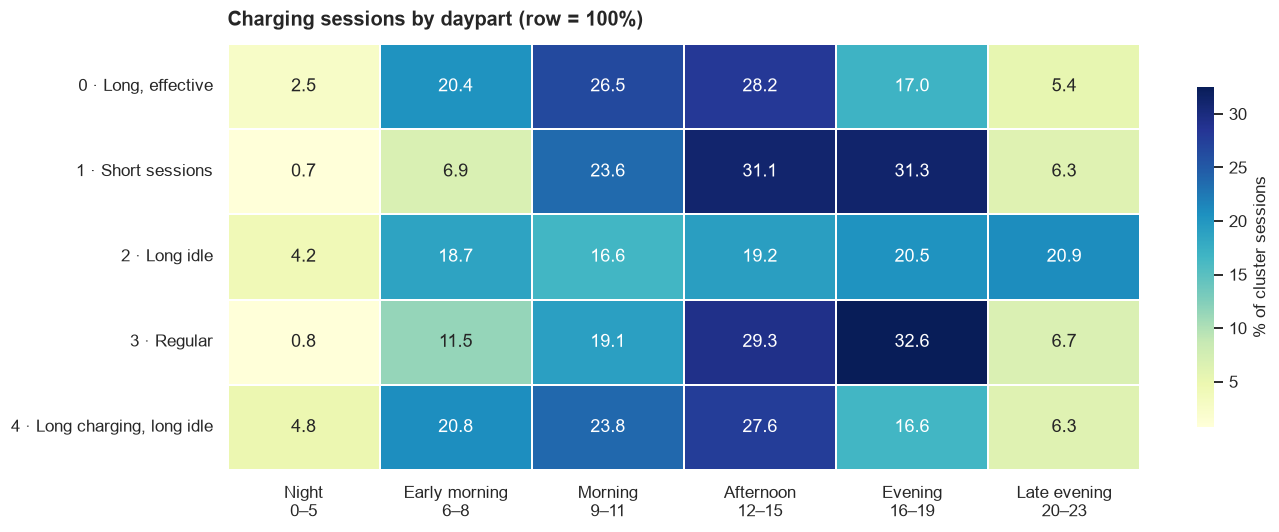

In [82]:
# 3b. dayparts (summary of the chart above)
DAYPART_BINS = [-1, 5, 8, 11, 15, 19, 23]
DAYPARTS = ["Night\n0–5", "Early morning\n6–8", "Morning\n9–11", "Afternoon\n12–15",
            "Evening\n16–19", "Late evening\n20–23"]
dc["daypart"] = pd.cut(dc["start_hour"], DAYPART_BINS, labels=DAYPARTS)
daypart_heatmap = pd.crosstab(dc["Cluster"], dc["daypart"], normalize="index") * 100

cluster_heatmap(daypart_heatmap, "Charging sessions by daypart (row = 100%)", fmt=".1f", cmap="YlGnBu")

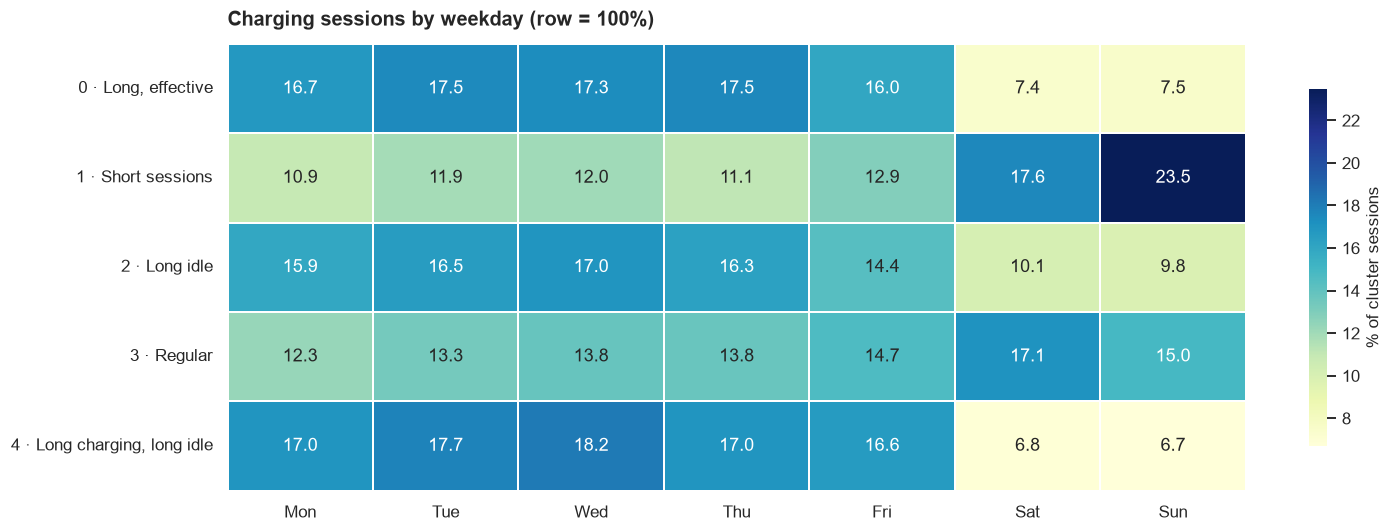

In [83]:
# 3c. weekday
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_heatmap = pd.crosstab(dc["Cluster"], dc["Start Date"].dt.dayofweek, normalize="index") * 100
weekday_heatmap.columns = WEEKDAYS

cluster_heatmap(weekday_heatmap, "Charging sessions by weekday (row = 100%)", fmt=".1f", cmap="YlGnBu")

### Conclusions:

Cluster 0 : Weekday users, start most often in the morning

Cluster 1 : Weekend users, mostly sunday, have 2 charging peaks (around 12 and 17), but most of the sessions takes place in the evening/ afternoon

Cluster 2 : Weekday users, quite evenly distributed throughout times of day but with a visible peak at 21 (which can explain the long idle time when leaving the car for the whole evening)

Cluster 3: spread across all days but mostly saturday and sunday, starts charging in the evenings

Cluster 4: Weekday, start primarily in the morning (and maybe leave their car plugged throughout the day)



## 4. Loyalty to one site

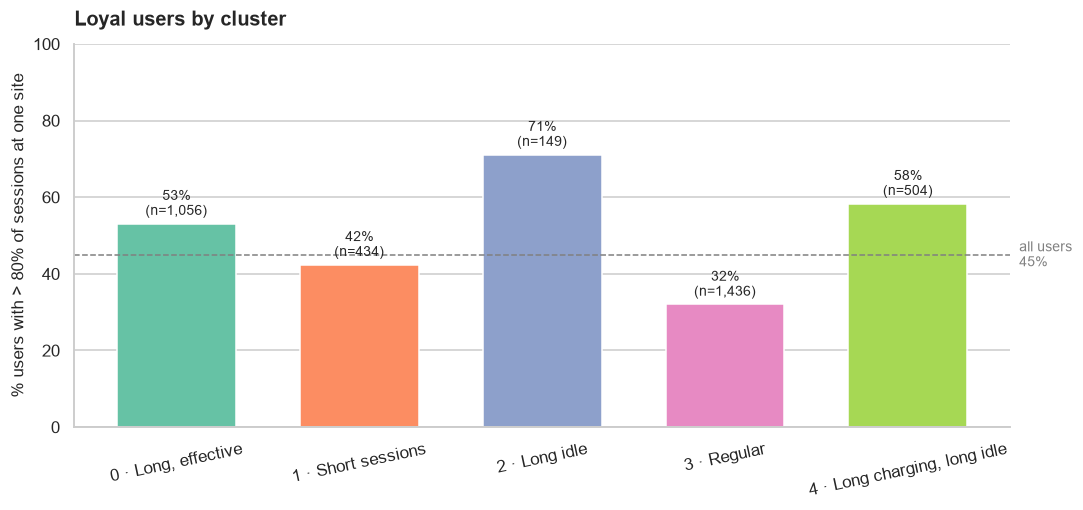

,users,loyal_pct,median_sites
Cluster,,,
"0 · Long, effective",1056,53.1,3.0
1 · Short sessions,434,42.4,3.0
2 · Long idle,149,71.1,2.0
3 · Regular,1436,32.0,3.0
"4 · Long charging, long idle",504,58.3,2.0


In [84]:
station_counts = dc.groupby(["User ID", "Cluster", "site"]).size().reset_index(name="sessions")
station_counts["user_sessions"] = station_counts.groupby("User ID")["sessions"].transform("sum")
station_counts["station_share"] = station_counts["sessions"] / station_counts["user_sessions"]

loyalty = station_counts.groupby(["User ID", "Cluster"]).agg(
    unique_stations=("site", "nunique"),
    top_station_share=("station_share", "max"),
).reset_index()

LOYAL_THRESHOLD = 0.8   # loyal = more than 80% of sessions at one site
loyalty["loyal_customer"] = loyalty["top_station_share"] > LOYAL_THRESHOLD
loyalty_by_cluster = loyalty.groupby("Cluster").agg(
    users=("loyal_customer", "size"),
    loyal_pct=("loyal_customer", lambda x: 100 * x.mean()),
    median_sites=("unique_stations", "median"),
)
overall_loyal = 100 * loyalty["loyal_customer"].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar([CLUSTER_LABELS[c] for c in loyalty_by_cluster.index], loyalty_by_cluster["loyal_pct"],
              color=[CLUSTER_COLORS[c] for c in loyalty_by_cluster.index], width=0.65)
ax.bar_label(bars, labels=[f"{v:.0f}%\n(n={n:,})" for v, n in
                           zip(loyalty_by_cluster["loyal_pct"], loyalty_by_cluster["users"])],
             padding=3, fontsize=9)
ax.axhline(overall_loyal, ls="--", c="grey", lw=1)
ax.text(1.01, overall_loyal, f"all users\n{overall_loyal:.0f}%", transform=ax.get_yaxis_transform(),
        ha="left", va="center", color="grey", fontsize=9)
ax.set_ylim(0, 100)
ax.set_ylabel(f"% users with > {LOYAL_THRESHOLD:.0%} of sessions at one site")
ax.set_title("Loyal users by cluster", loc="left")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

display(loyalty_by_cluster.rename(index=CLUSTER_LABELS).round(1))

### Conclusions:

* Long idle and long charging+long idle are the most loyal clusters with more than half of their users visiting primarily one site. Carefull : This does not mean users from cluster 2 prefer the SAME SITE, but rather each user strongly prefers their own site. 

* Regular users seem to be the least loyal, meaining they can charge at multiple various stations

* Regular users and short sessions were also weekend users, this may suggest they just charge "on the way" to different places and therefore the location switch. While users from Clusters 0 and 4 start on the weekdays in the morning (maybe before work) and therefore they often use the same site.

## 5. Trends over time

If in a month the number of users from cluster K was less than 20, we do not display this averages on the plot since its too little users.

In [91]:
MIN_USERS = 20     # hide cluster-months with fewer active users
ROLL = 3           # rolling window in months

dc["month"] = dc["Start Date"].dt.to_period("M").dt.to_timestamp()

# monthly statistics per cluster
user_month = dc.groupby(["Cluster", "month", "User ID"])["Energy (kWh)"].sum().reset_index()
monthly = dc.groupby(["Cluster", "month"]).agg(
    avg_energy_session=("Energy (kWh)", "mean"),
    active_users=("User ID", "nunique"),
).join(user_month.groupby(["Cluster", "month"])["Energy (kWh)"].mean().rename("avg_energy_user"))
monthly = monthly.reset_index()

# key dates
paid_share = (dc["Fee"].fillna(0) > 0).groupby(dc["month"]).mean()
FEE_START = paid_share[paid_share > 0.5].index.min()
COVID_START = pd.Timestamp("2020-03-01")
print("Fees introduced (first month with > 50% paid sessions):", FEE_START.strftime("%Y-%m"))


def wide(col, mask=True, roll=ROLL):
    # month x cluster table, small cluster-months hidden, optional smoothing
    t = monthly.pivot(index="month", columns="Cluster", values=col)
    if mask:
        users = monthly.pivot(index="month", columns="Cluster", values="active_users")
        t = t.where(users >= MIN_USERS)
    return t.rolling(roll, min_periods=1, center=True).mean() if roll else t


def trend_plot(table, title, ylabel, ax=None, legend=True):
    ax = ax or plt.subplots(figsize=(13, 4.8))[1]
    for c in table.columns:
        ax.plot(table.index, table[c], lw=2.2, color=CLUSTER_COLORS[c], label=CLUSTER_LABELS[c])
    for date, name in [(FEE_START, "fees introduced"), (COVID_START, "COVID-19")]:
        ax.axvline(date, ls="--", c="grey", lw=1)
        ax.text(date, ax.get_ylim()[1], f" {name}", va="top", ha="left", fontsize=9, color="grey")
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    if legend:
        ax.legend(loc="upper left", fontsize=9)
    return ax

Fees introduced (first month with > 50% paid sessions): 2017-08


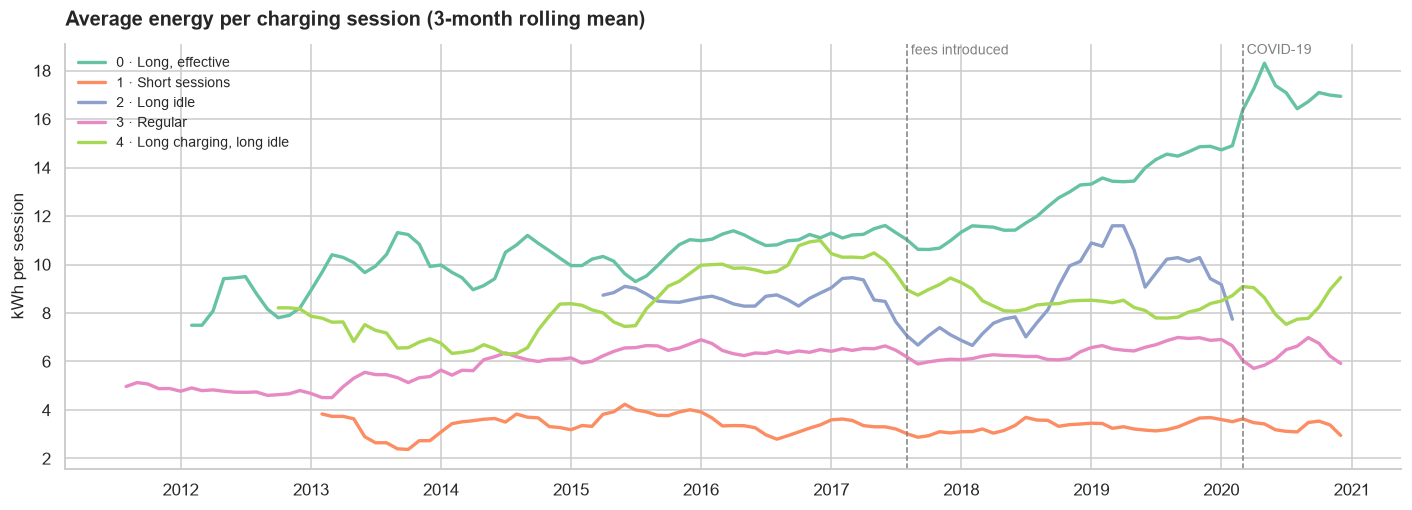

In [92]:
# 5a. average energy per session
trend_plot(wide("avg_energy_session"), "Average energy per charging session (3-month rolling mean)", "kWh per session")
plt.tight_layout()
plt.show()

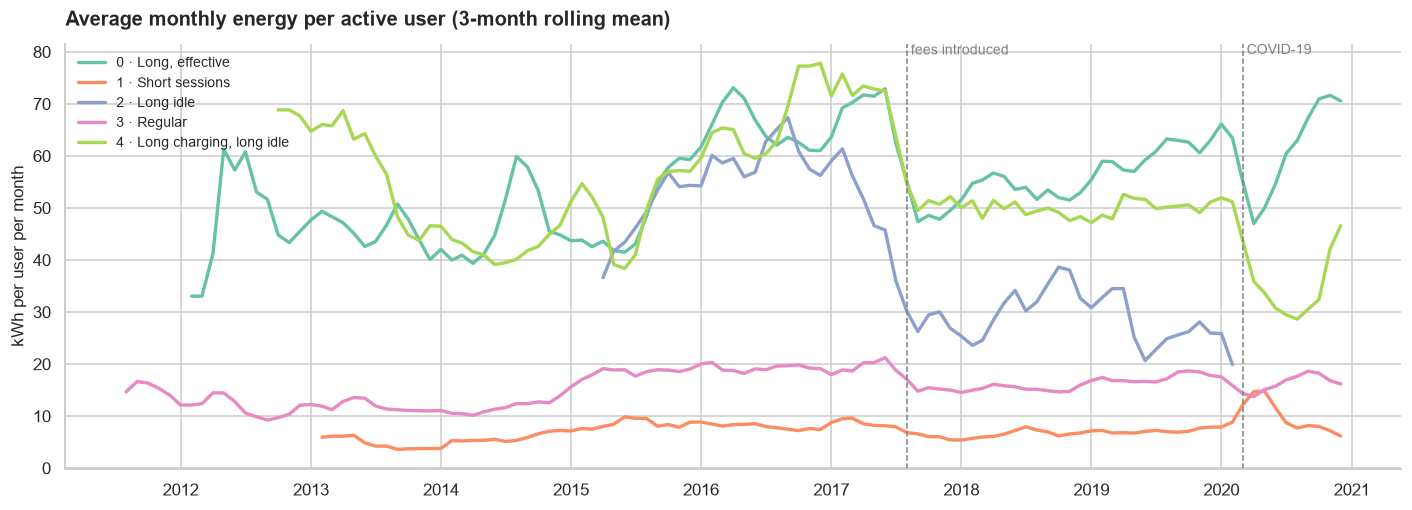

In [93]:
# 5b. average monthly energy per user
trend_plot(wide("avg_energy_user"), "Average monthly energy per active user (3-month rolling mean)", "kWh per user per month")
plt.tight_layout()
plt.show()

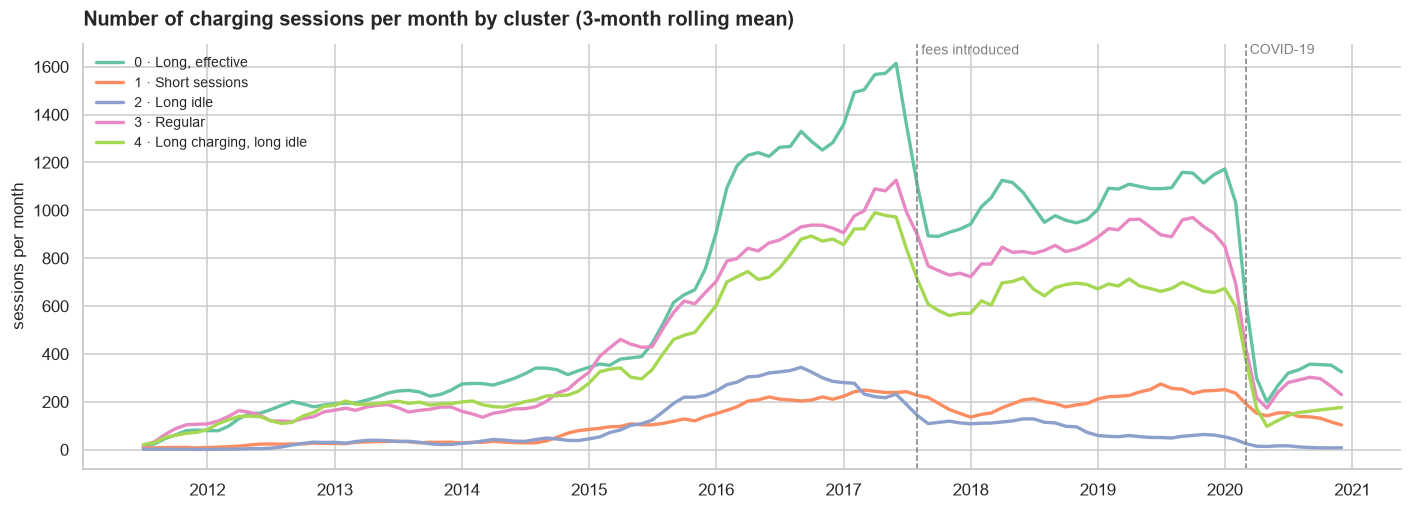

In [94]:
sessions_month = dc.groupby(["month", "Cluster"]).size().unstack("Cluster")
sessions_month = sessions_month.rolling(ROLL, min_periods=1, center=True).mean()

trend_plot(sessions_month, "Number of charging sessions per month by cluster (3-month rolling mean)",
           "sessions per month")
plt.tight_layout()
plt.show()

### Conclusions 

* Clusters reacted differently to fees in 2017. Number of sessions within clisters 1 and 2 remained the same while for cluster 0,3,4 we see a sharp drop in the overall number of sessions

* Avg evergy per session remained unchaged, but we see a high drop in evergy per user. The highest difference was for heavy clusters (0,2,4) and with comparison to the other plots it was a result of less visits on the stations. 

* in mid 2020 the number of sessions dropped again due to covid

## 6. Overnight charging

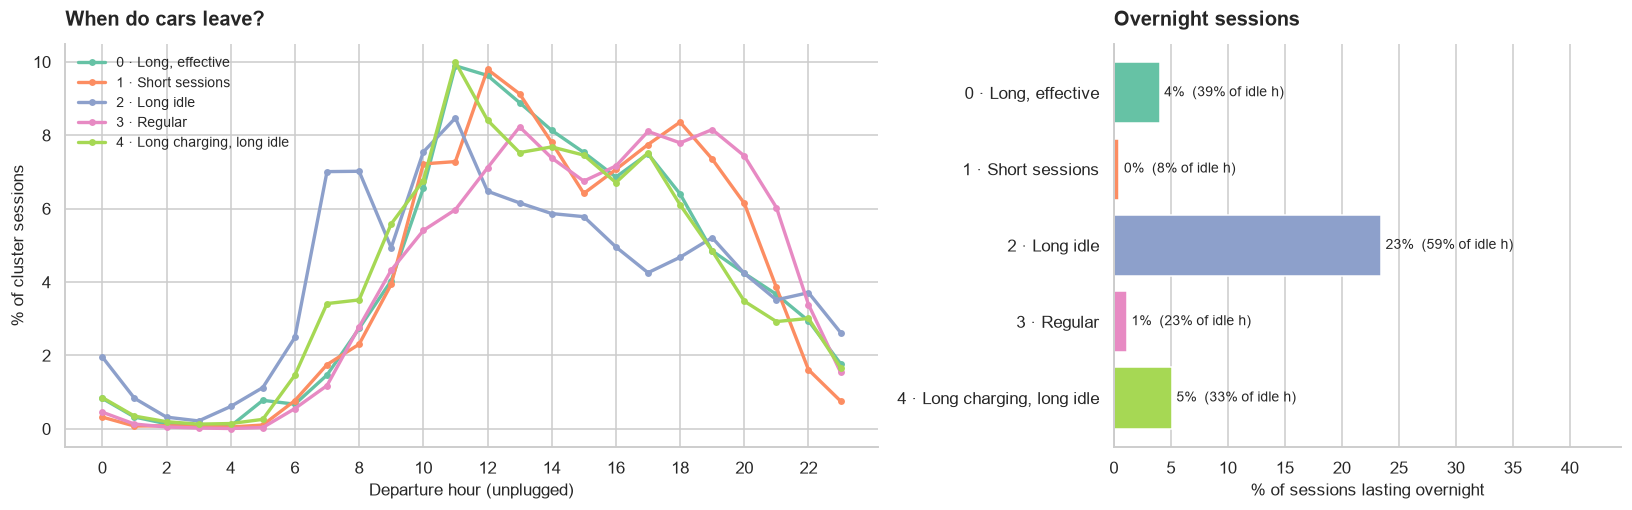

,overnight_pct,overnight_idle_share
Cluster,,
"0 · Long, effective",4.0,38.9
1 · Short sessions,0.5,8.0
2 · Long idle,23.4,59.0
3 · Regular,1.1,22.7
"4 · Long charging, long idle",5.1,33.4


In [96]:
dc["end_hour"] = dc["End Date"].dt.hour
dc["overnight"] = dc["End Date"].dt.normalize() > dc["Start Date"].dt.normalize()

departure = pd.crosstab(dc["end_hour"], dc["Cluster"], normalize="columns").reindex(range(24), fill_value=0) * 100
overnight = dc.groupby("Cluster").agg(
    overnight_pct=("overnight", lambda x: 100 * x.mean()),
    overnight_idle_share=("idle_hours", lambda x: 100 * x[dc.loc[x.index, "overnight"]].sum() / x.sum()),
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
for c in CLUSTER_ORDER:
    axes[0].plot(departure.index, departure[c], marker="o", ms=3.5, lw=2.2,
                 color=CLUSTER_COLORS[c], label=CLUSTER_LABELS[c])
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("Departure hour (unplugged)")
axes[0].set_ylabel("% of cluster sessions")
axes[0].set_title("When do cars leave?", loc="left")
axes[0].legend(fontsize=9)

names = [CLUSTER_LABELS[c] for c in overnight.index]
b = axes[1].barh(names, overnight["overnight_pct"], color=[CLUSTER_COLORS[c] for c in overnight.index])
axes[1].bar_label(b, labels=[f"{p:.0f}%  ({s:.0f}% of idle h)" for p, s in
                             zip(overnight["overnight_pct"], overnight["overnight_idle_share"])],
                  padding=3, fontsize=9)
axes[1].set_xlim(0, overnight["overnight_pct"].max() * 1.9)
axes[1].invert_yaxis()
axes[1].set_xlabel("% of sessions lasting overnight")
axes[1].set_title("Overnight sessions", loc="left")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(overnight.rename(index=CLUSTER_LABELS).round(1))

### Conclusions

We confirm that many of the Cluster 2 user sessions are happening overnight. 

# Possible recommendations for this clustering:

1) Long idle time is mainly caused by users from cluster 2 and 4, but the problem is not directed at any specific station, but rather across the whole city. Recommendation : Send SMS reminders about the ending of charging; 

2) However, we checked that many idle hours are due to overnight charging (when demand is low either way) and after introducing fees the number of sessions for users in cluster 2 dropped and never bounced back - maybe not to loose those customers (or attract them back) due to high fees, the fees for stalling should be only for the day, when there is a risk they are in fact taking someone's place. (prepare some night offer to attract the stallers at night to unblock the chargers during the day)

3) Cluster 0 as the most valuable customers - they have the largest amount of sessions and used energy, meaning they generate the highest revenue. They are also loyal to their preferred site. Recommendation : keep those users. They charge mostly on weekday mornings - make sure to have the chargers available, penalize idle time even more during that time, introduce some yearly abonament for those regular users (on their station).

4) Clusters 0 and 4 as the most valuable user groups - (a) they are most loyal to one station: recommendation to introduce some point system/discounts for regular customers (b) they bounced back after a sharp drop of sessions after fee introduction 
